In [4]:
%pip install torchvision numpy pandas opencv-python kaggle

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: C:\Users\DELL\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
import torch
import torchvision
import numpy as np
import pandas as pd
import cv2

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

torch: 2.13.0+cpu
torchvision: 0.28.0+cpu
CUDA available: False


In [8]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

In [9]:
# Image size after resizing to  32 x 32
IMG_SIZE = 32

# Number of images processed at one time
BATCH_SIZE = 64

# Transformations to apply to every image
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

In [10]:
#loading dataset

dataset = datasets.ImageFolder(
    root="E:/Projects/Crack_detection/surface-crack-detection",  
    transform=transform
)

print("Classes:", dataset.classes)
print("Total Images:", len(dataset))

Classes: ['Negative', 'Positive']
Total Images: 40000


In [12]:
# 70% Training
train_size = int(0.7 * len(dataset))  #initialized only, not randomized yet

# Remaining 30% Validation
val_size = len(dataset) - train_size

# Split randomly  (now it is randomized, 70% train, 30% test)
train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size]
)

# Create batches 
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True  #suppose if all images initially are positive, we dont want model to train poorly, so we shuffle stuff 
                  # in batches, this is for training. For testing, we dont need shuffling, so false 
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)



In [13]:
print("Training Images :", len(train_dataset))
print("Validation Images :", len(val_dataset))

print("Training Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))

Training Images : 28000
Validation Images : 12000
Training Batches : 438
Validation Batches : 188


In [14]:
#verify data size before testing
images, labels = next(iter(train_loader))

print("Image Batch Shape :", images.shape)
print("Label Shape :", labels.shape)

print("First 10 Labels :", labels[:10])

Image Batch Shape : torch.Size([64, 3, 32, 32])
Label Shape : torch.Size([64])
First 10 Labels : tensor([0, 1, 1, 1, 1, 1, 1, 0, 0, 1])


In [15]:
import torch.nn as nn
import torch.optim as optim  #optimizers 

In [16]:
#now the neural network would be written 
class CrackCnn(nn.Module):
    def __init__(self):
        super().__init__()

        #first conv layer
        self.conv1=nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)

         # Second Convolution Layer
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Activation
        self.relu = nn.ReLU()

        # Pooling
        self.pool = nn.MaxPool2d(kernel_size=2)

        # Fully Connected Layers
        self.fc1 = nn.Linear(32 * 8 * 8, 64)
        self.fc2 = nn.Linear(64, 2)

    def forward(self, x):

        # 32x32 -> 16x16
        x = self.pool(self.relu(self.conv1(x)))

        # 16x16 -> 8x8
        x = self.pool(self.relu(self.conv2(x)))

        # Flatten
        x = x.view(x.size(0), -1)

        # Dense Layer
        x = self.relu(self.fc1(x))

        # Output Layer
        x = self.fc2(x)

        return x
    



In [29]:
import torch.nn as nn

class CrackCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # -------- Block 1 --------
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.relu = nn.ReLU()

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # -------- Block 2 --------
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # -------- Block 3 --------
        self.conv3 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Fully Connected Layers
        self.fc1 = nn.Linear(128 * 4 * 4, 256)

        self.fc2 = nn.Linear(256, 2)

    def forward(self, x):

        # Block 1
        x = self.pool(self.relu(self.conv1(x)))

        # Block 2
        x = self.pool(self.relu(self.conv2(x)))

        # Block 3
        x = self.pool(self.relu(self.conv3(x)))

        # Flatten
        x = x.view(x.size(0), -1)

        # Dense Layer
        x = self.relu(self.fc1(x))

        # Dropout
        x = self.dropout(x)

        # Output
        x = self.fc2(x)

        return x

In [30]:
# Create CNN
#model = CrackCnn()  #model changing to paper model in next line
model = CrackCNN()
# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

CrackCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (dropout): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=2, bias=True)
)


In [31]:
# Number of times the model will see the entire training dataset
EPOCHS = 2

for epoch in range(EPOCHS):

    running_loss = 0.0

    # Loop through every batch
    for images, labels in train_loader:

        # Remove old gradients
        optimizer.zero_grad()

        # Forward Pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Add batch loss
        running_loss += loss.item()

    # Print loss after every epoch
    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {running_loss/len(train_loader):.4f}")

KeyboardInterrupt: 

In [20]:
correct = 0
total = 0

# Turn off gradient calculation during testing
with torch.no_grad():

    for images, labels in val_loader:

        outputs = model(images)

        # Predicted class
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Validation Accuracy: {accuracy:.2f}%")

Validation Accuracy: 97.47%


In [22]:
!pip install scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: C:\Users\DELL\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.4 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/8.2 MB 1.4 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.2 MB 1.3 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.2 MB 1.3 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.2 MB 1.4 MB/s eta 0:00:05
   ----------- ---------------------------- 2.4/8.2 MB 1.5 MB/s eta 0:00:04
   -------------- ------------------------- 2.9/8.2 MB 1.6 MB/s eta 0:00:04
   --------------- ------------------------ 3.1/8.2 MB 1.7 MB/s eta 0:00:03
   ---------------- ----------------------- 3.4/8.2 MB 1.7 MB/s eta 0:00:03
   -------------------- -------

In [23]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

In [24]:
model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in val_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predicted.numpy())

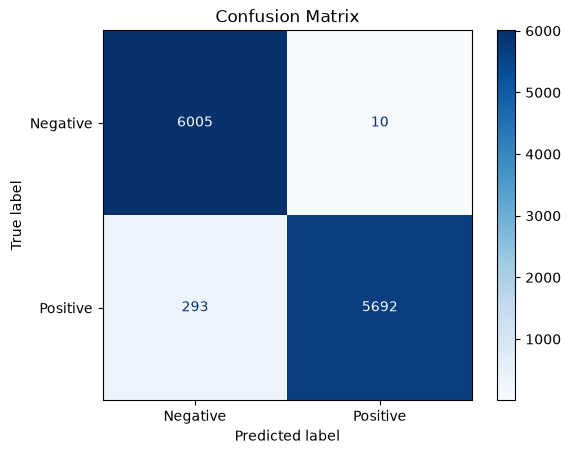

In [25]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [26]:
precision = precision_score(all_labels, all_predictions)
recall = recall_score(all_labels, all_predictions)
f1 = f1_score(all_labels, all_predictions)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Precision : 0.9982
Recall    : 0.9510
F1 Score  : 0.9741


In [27]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
))

              precision    recall  f1-score   support

    Negative       0.95      1.00      0.98      6015
    Positive       1.00      0.95      0.97      5985

    accuracy                           0.97     12000
   macro avg       0.98      0.97      0.97     12000
weighted avg       0.98      0.97      0.97     12000



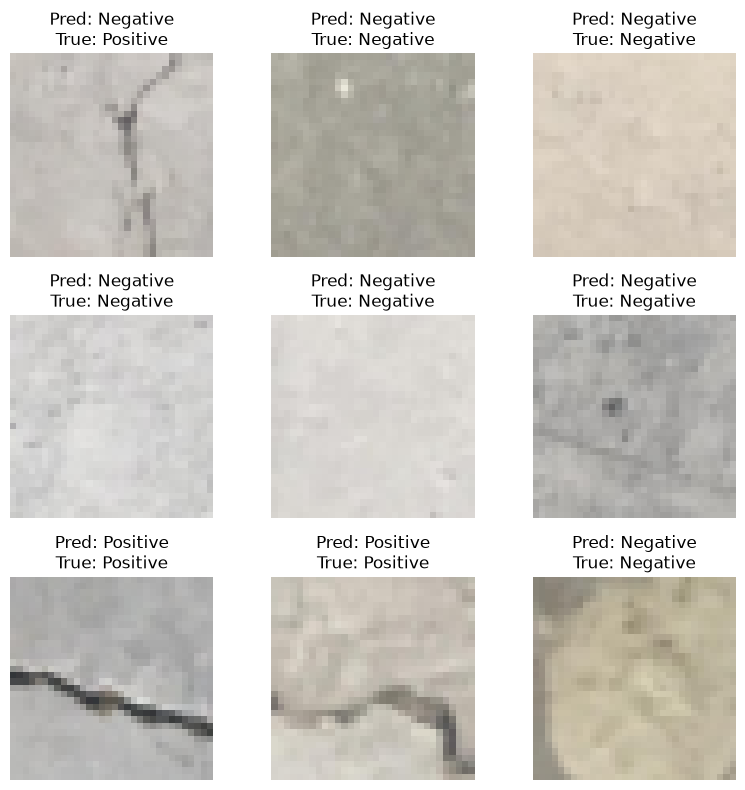

In [28]:
import random

model.eval()

fig, axes = plt.subplots(3, 3, figsize=(8,8))

indices = random.sample(range(len(val_dataset)), 9)

for ax, idx in zip(axes.flatten(), indices):

    image, label = val_dataset[idx]

    with torch.no_grad():

        output = model(image.unsqueeze(0))

        _, prediction = torch.max(output, 1)

    img = image.permute(1,2,0).numpy()

    ax.imshow(img)

    ax.set_title(
        f"Pred: {dataset.classes[prediction.item()]}\nTrue: {dataset.classes[label]}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()